In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem2
import optimiser_problem2_new_new as optimiser_problem2
from math import factorial
import pickle

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
sigma_s = 1e-1
b1 = 1e-3
b3 = 1e-2
sigma2 = 1

params = {'b0': 1, 'b1': b1, 'b2': 1, 'b3': b3,
          'sigma0': 1, 'sigma2': sigma2, 'k': 1e-3, 
          'theta1': 10, 'theta2': 1e-2, 'S0': 100, 'Q0': 10, 'X0': 0, 
          'T': 0.10, 'Nt': 1_000}

env = problem2.environment(**params)

In [3]:
np.random.seed(456)
dim = 2
order = 6

with open('W_sig_1.pkl', 'rb') as f:
    W_sig = pickle.load(f)
    f.close()

# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()
    
#env = problem2.environment(**params)
optimiser_1 = optimiser_problem2.Optimiser(env, W_sig, order = order)
#F = ta.sig_to_tensor(F, optimiser_1.dim, optimiser_1.order)

In [4]:
#optimiser_1.F = F

In [5]:
np.random.seed(456)
trunc_lev = 4
trunc_lev_1 = 4
n_epochs = 100
lr = 10

optimiser_1.train_sgd(n_epochs, lr = lr, trunc_lev_s = trunc_lev, method='SGD')

F = optimiser_1.F

strag_sig = problem2.sig_strag_dot(F, order = order)

[1026.88458499]: 100%|███████████████████████████████████████████████████████████████| 100/100 [07:56<00:00,  4.76s/it]


In [6]:
with open('F_optimised_problem2.pkl', 'wb') as f:
    pickle.dump(F.flatten(), f)
    f.close()

In [7]:
np.random.seed(123)

nsims = 10

env.simulate(nsims, strag_sig)

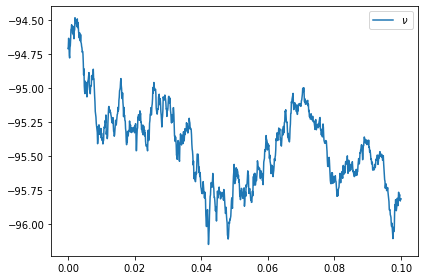

In [8]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
print(f'Performance criterion\nSig: {env.run_crit[-1,:].mean()}')
print(f'Wealth\nSig: {env.wealth[-1,:].mean()}')

Performance criterion
Sig: 1028.5070332133816
Wealth
Sig: 1085.1461155311304


In [10]:
optimiser_1.value_fn(F.flatten(), trunc_lev_s = trunc_lev)

-1026.8864557787888

In [11]:
# f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

LF = optimiser_1.LF
p_perf = optimiser_1.p_perf

f_s_sig = problem2.sig_strag_dot(LF, order = trunc_lev)
f_perf_crit = problem2.sig_strag_dot(p_perf, order = order)

S_sig = np.zeros((env.Nt+1,nsims))
perf_hist = np.zeros((env.Nt+1,nsims))

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(env.Nt+1):
    S_sig[it,:] = f_s_sig(env,it)
    perf_hist[it,:] = f_perf_crit(env,it)
    #S_sig[it,:] = strag_sig(env,it)

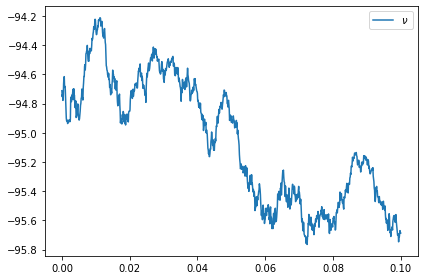

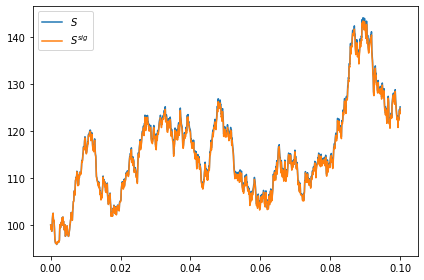

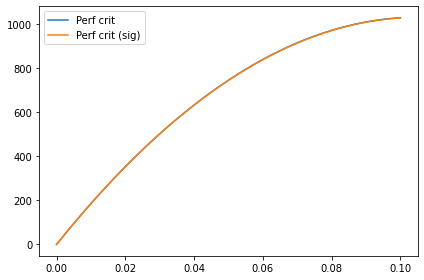

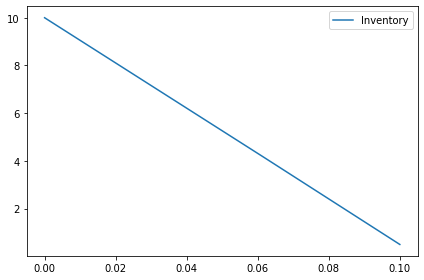

In [12]:
nsim = 9

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.plot(env.timesteps, S_sig[:,nsim], label=r'$S^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:,nsim], label=r'Perf crit (sig)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.Q[:,nsim], label=r'Inventory')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
env.Q

array([[10.        , 10.        , 10.        , ..., 10.        ,
        10.        , 10.        ],
       [ 9.99052888,  9.99052888,  9.99052888, ...,  9.99052888,
         9.99052888,  9.99052888],
       [ 9.98105264,  9.98106206,  9.98105886, ...,  9.98105564,
         9.98106325,  9.98105364],
       ...,
       [ 0.41848017,  0.51197212,  0.47806224, ...,  0.37811627,
         0.50772703,  0.51317806],
       [ 0.40881643,  0.50237887,  0.46847901, ...,  0.36810828,
         0.49817641,  0.50361102],
       [ 0.39915387,  0.49278767,  0.4588974 , ...,  0.35809915,
         0.48862685,  0.49404228]])